In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression


from sklearn.preprocessing import StandardScaler

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

from sklearn.metrics import (mean_absolute_error,mean_squared_error,r2_score)

Purpuse :--

Pandas :- manipulate data,
Numpy :-- mathamtical operations,
Seaborn :-- statistics visuals,
Matplotlib :-- graphs,
Scikit learn :-- ML model.



In [8]:
df = pd.read_csv('./Housing.csv')
df.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   price             545 non-null    int64 
 1   area              545 non-null    int64 
 2   bedrooms          545 non-null    int64 
 3   bathrooms         545 non-null    int64 
 4   stories           545 non-null    int64 
 5   mainroad          545 non-null    object
 6   guestroom         545 non-null    object
 7   basement          545 non-null    object
 8   hotwaterheating   545 non-null    object
 9   airconditioning   545 non-null    object
 10  parking           545 non-null    int64 
 11  prefarea          545 non-null    object
 12  furnishingstatus  545 non-null    object
dtypes: int64(6), object(7)
memory usage: 55.5+ KB


In [10]:
df.describe()

,price,area,bedrooms,bathrooms,stories,parking
count,5.450000e+02,545.000000,545.000000,545.000000,545.000000,545.000000
mean,4.766729e+06,5150.541284,2.965138,1.286239,1.805505,0.693578
std,1.870440e+06,2170.141023,0.738064,0.502470,0.867492,0.861586
min,1.750000e+06,1650.000000,1.000000,1.000000,1.000000,0.000000
25%,3.430000e+06,3600.000000,2.000000,1.000000,1.000000,0.000000
50%,4.340000e+06,4600.000000,3.000000,1.000000,2.000000,0.000000
75%,5.740000e+06,6360.000000,3.000000,2.000000,2.000000,1.000000
max,1.330000e+07,16200.000000,6.000000,4.000000,4.000000,3.000000


In [11]:
df.describe(include='object')

,mainroad,guestroom,basement,hotwaterheating,airconditioning,prefarea,furnishingstatus
count,545,545,545,545,545,545,545
unique,2,2,2,2,2,2,3
top,yes,no,no,no,no,no,semi-furnished
freq,468,448,354,520,373,417,227


heck missing values and duplicated

In [12]:
df.isnull().sum()

,0
price,0
area,0
bedrooms,0
bathrooms,0
stories,0
mainroad,0
guestroom,0
basement,0
hotwaterheating,0
airconditioning,0


In [13]:
df.duplicated().sum()

np.int64(0)

Exploratory Data Analysis

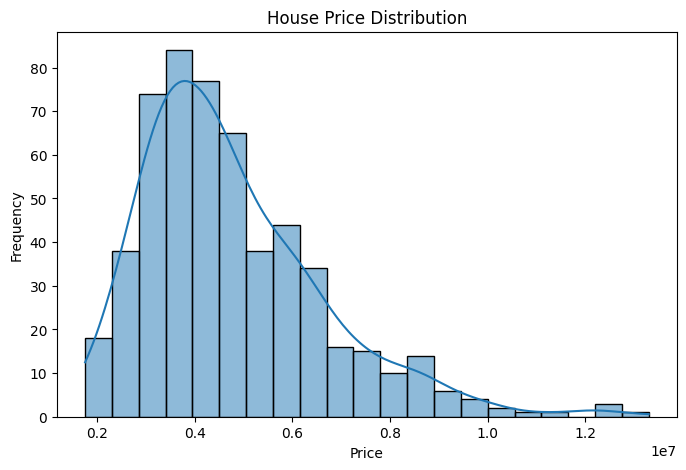

In [14]:
plt.figure(figsize=(8,5))
sns.histplot(df['price'],kde=True)
plt.title("House Price Distribution")
plt.xlabel("Price")
plt.ylabel("Frequency")
plt.show()

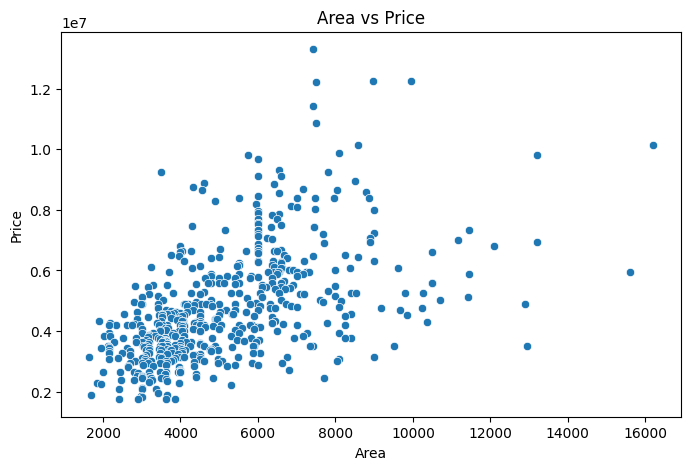

In [15]:
plt.figure(figsize=(8,5))
sns.scatterplot(x='area',y='price',data=df)
plt.title("Area vs Price")
plt.xlabel("Area")
plt.ylabel("Price")
plt.show()

Correlation Heatmap

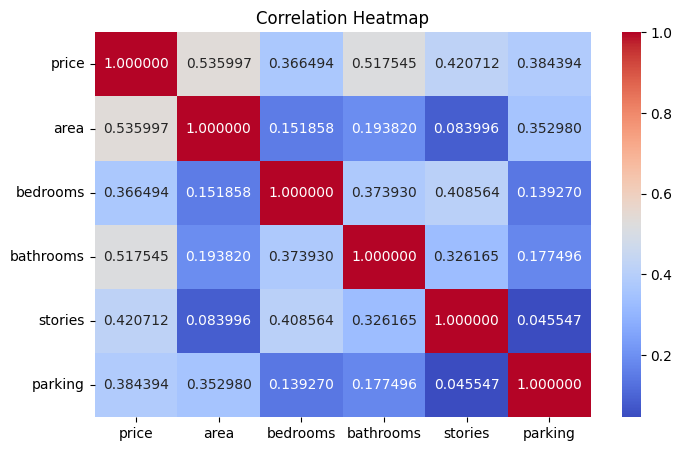

In [16]:
plt.figure(figsize=(8,5))
sns.heatmap(
    df.select_dtypes(include=[np.number]).corr(),
    cmap="coolwarm",
    fmt="2f",
    annot=True)
plt.title("Correlation Heatmap")
plt.show()

Feautre Extract :--

In [17]:
x = df.drop('price', axis=1)
y = df['price']

In [18]:
x

,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished
...,...,...,...,...,...,...,...,...,...,...,...,...
540,3000,2,1,1,yes,no,yes,no,no,2,no,unfurnished
541,2400,3,1,1,no,no,no,no,no,0,no,semi-furnished
542,3620,2,1,1,yes,no,no,no,no,0,no,unfurnished
543,2910,3,1,1,no,no,no,no,no,0,no,furnished


In [19]:
y

,price
0,13300000
1,12250000
2,12250000
3,12215000
4,11410000
...,...
540,1820000
541,1767150
542,1750000
543,1750000


In [20]:
x.shape

(545, 12)

In [21]:
y.shape

(545,)

Train_test_split :--

In [22]:
x_train, x_test, y_train, y_test = train_test_split(x,y,test_size=0.20, random_state=42)

In [23]:
x_train.shape

(436, 12)

In [24]:
x_test.shape

(109, 12)

Identify Numerical And catagorical Columns:--

Machine Learning Algorithm :--

Linear Regression :--(multi)

Identifying Numerical Datasets :--

In [25]:
numeric_features = x.select_dtypes(include=["int64","float64"]).columns.tolist()
numeric_features

['area', 'bedrooms', 'bathrooms', 'stories', 'parking']

Catagorical Features :--

In [26]:
categorical_features = x.select_dtypes(include=["object"]).columns.tolist()
categorical_features

['mainroad',
 'guestroom',
 'basement',
 'hotwaterheating',
 'airconditioning',
 'prefarea',
 'furnishingstatus']

In [27]:
x[["area","bedrooms"]]

,area,bedrooms
0,7420,4
1,8960,4
2,9960,3
3,7500,4
4,7420,4
...,...,...
540,3000,2
541,2400,3
542,3620,2
543,2910,3


Standardization of Numerical Data:--

In [28]:
scaler = StandardScaler()
scaled_data = scaler.fit_transform(x_train[numeric_features])
scaled_data


array([[ 0.38416819,  0.05527092,  1.53917323,  2.58764353,  0.36795665],
       [ 0.9291807 ,  0.05527092,  1.53917323, -0.91249891,  2.70998729],
       [-0.60775457, -1.28351359, -0.5579503 , -0.91249891,  1.53897197],
       ...,
       [-0.29709744,  0.05527092,  1.53917323,  1.42092939,  0.36795665],
       [-0.5060189 , -1.28351359, -0.5579503 , -0.91249891, -0.80305867],
       [ 0.15707965,  0.05527092,  1.53917323,  2.58764353,  0.36795665]],
      shape=(436, 5))

In [29]:
x_train[categorical_features]

,mainroad,guestroom,basement,hotwaterheating,airconditioning,prefarea,furnishingstatus
46,yes,no,no,no,yes,no,furnished
93,yes,no,yes,no,yes,no,semi-furnished
335,yes,no,yes,no,yes,no,furnished
412,yes,no,yes,no,no,yes,unfurnished
471,yes,no,no,no,no,no,unfurnished
...,...,...,...,...,...,...,...
71,yes,no,no,no,yes,no,unfurnished
106,yes,no,yes,no,yes,yes,semi-furnished
270,yes,no,no,yes,no,no,furnished
435,yes,no,no,no,no,no,unfurnished


one hot encoding:---

In [30]:
from sklearn.preprocessing import OneHotEncoder

emcoder = OneHotEncoder(handle_unknown="ignore",drop="first")
encoder_data = emcoder.fit_transform(x_train[categorical_features])
encoder_data.toarray()

array([[1., 0., 0., ..., 0., 0., 0.],
       [1., 0., 1., ..., 0., 1., 0.],
       [1., 0., 1., ..., 0., 0., 0.],
       ...,
       [1., 0., 0., ..., 0., 0., 0.],
       [1., 0., 0., ..., 0., 0., 1.],
       [1., 1., 0., ..., 0., 1., 0.]], shape=(436, 8))

Handle unknown :-- New category appers during....Prideiction _ wont crash...
Monitoring - new data - Unknown category

Drop First :-- it will remove one refrence category from each feature.
Reduce :-- multicollinearity....

Multicolinearity :--

Building Columns Transform :--

Columns :-- Dataset ke columns/Features...
Transformer :-- Data per koi Transformation apply karna...

So columns Transformer is a scikit - learn tool that applies different pre - processing tachnique to different columns of same datasets....



har columns ko uski requrment ke according process karna...

One Hot Encoding solo per nhi lagega

Instead of Transforming numerical and categorical columns seperatly everytime,we can automate the process using ColumnTransmer...

From sklearn.compose columntransform
from sklearn,impute simpleimpute
from sklearn.pipeline pipeline

In [31]:
preprocessor = ColumnTransformer(
    transformers=[
    ("numeric",StandardScaler(),numeric_features),
    ("categorical",OneHotEncoder(handle_unknown="ignore",drop="first"),categorical_features)
]
)
preprocessor

ColumnTransformer(transformers=[('numeric', StandardScaler(),
                                 ['area', 'bedrooms', 'bathrooms', 'stories',
                                  'parking']),
                                ('categorical',
                                 OneHotEncoder(drop='first',
                                               handle_unknown='ignore'),
                                 ['mainroad', 'guestroom', 'basement',
                                  'hotwaterheating', 'airconditioning',
                                  'prefarea', 'furnishingstatus'])])

In [32]:
from sklearn.pipeline import Pipeline

model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("regressor", LinearRegression())
    ]
)
model

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numeric', StandardScaler(),
                                                  ['area', 'bedrooms',
                                                   'bathrooms', 'stories',
                                                   'parking']),
                                                 ('categorical',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore'),
                                                  ['mainroad', 'guestroom',
                                                   'basement',
                                                   'hotwaterheating',
                                                   'airconditioning',
                                                   'prefarea',
                                                   'furnishingstatus'])])),
                ('regressor', LinearRegression())])

What is Pipeline :--
Raw input -- preprocessing-- feature engineering---linear regression--prediction

Pipeline connects ML workflow....

Data Leakage Prevented

Preprocessing model is kept together...
prediction on raw input data becomes easy...
cross - validation & hyperparameter tuning will became easy...

MOdel Train --- model.fit(x_train,y_train)

In [33]:
model.fit(x_train,y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numeric', StandardScaler(),
                                                  ['area', 'bedrooms',
                                                   'bathrooms', 'stories',
                                                   'parking']),
                                                 ('categorical',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore'),
                                                  ['mainroad', 'guestroom',
                                                   'basement',
                                                   'hotwaterheating',
                                                   'airconditioning',
                                                   'prefarea',
                                                   'furnishingstatus'])])),
                ('regressor', LinearRegression())])

What is happening internally:--
1) Preprocessor hai wo learn karra hai from training data...
2) Numerical data jo bhi tha wo scale hogya...
3) categorical data jo bhi tha wo One Hot Encode hogya...
4) Linear Reggression cofficents lean hogya...
5)Model learn the relation between features & target price...

Model --- Pridict

In [34]:
y_pred = model.predict(x_test)
y_pred

array([5164653.90033967, 7224722.29802166, 3109863.24240338,
       4612075.3272256 , 3294646.25725956, 3532275.09556558,
       5611774.56836474, 6368145.98732718, 2722856.95689986,
       2629405.61585783, 9617039.50315579, 2798087.30447888,
       3171096.76847064, 3394639.09125528, 3681088.65424275,
       5263187.74621486, 3035963.47612385, 4786122.8004005 ,
       4349551.9200572 , 3572362.09930451, 5774875.2139565 ,
       5886993.57919883, 2730836.19518458, 4727316.47323636,
       5244847.52716799, 7555324.21605601, 3220790.84680269,
       5191898.79934207, 8143726.91009782, 3398814.09825035,
       6490693.05027925, 3315105.90747811, 6708457.36761325,
       4201738.21071676, 3557571.06735186, 5836974.50478626,
       4808660.67448475, 4362878.73613262, 3191242.95701508,
       4596554.93225239, 4566042.8604841 , 3517779.52374148,
       7205844.79365835, 3983597.27861103, 3749338.70271055,
       4274731.09125895, 6757442.10783741, 4037320.43665852,
       3769334.90397125,

Comparrision karna hai
y_test store kiya hua tha and
y_pred me kya kya values show ho re hai...

In [35]:
comparison = pd.DataFrame({"Actual":y_test,"Predicted":y_pred})
comparison.head()

,Actual,Predicted
316,4060000,5.164654e+06
77,6650000,7.224722e+06
360,3710000,3.109863e+06
90,6440000,4.612075e+06
493,2800000,3.294646e+06


In [36]:
mse = mean_squared_error(y_test,y_pred)
mse

1754318687330.6667

In [37]:
mae = mean_absolute_error(y_test,y_pred)
mae

970043.403920164

In [38]:
r2 = r2_score(y_test,y_pred)
r2

0.6529242642153178

In [39]:
rmse = np.sqrt(mse)
rmse

np.float64(1324506.9600914398)

In [40]:
evaluate = pd.DataFrame(
    {
        "Model":["Linear Regression"],
        "MSE":[mse],
        "MAE":[mae],
        "RMSE":[rmse],
        "R2 Score":[r2]
    }
)
evaluate

,Model,MSE,MAE,RMSE,R2 Score
0,Linear Regression,1.754319e+12,970043.40392,1.324507e+06,0.652924
